In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty, corrected_field, corrected_field_error
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


In [2]:
import glob

all_freq_sweeps = glob.glob("data/25/*kHz_*.npz")

all_data_numbers = {} #dictionary of frequency: list of data numbers
for sweep in all_freq_sweeps:
    freq = int(sweep.split("25\\")[-1].split("kHz_")[0])
    dnum = int(sweep.split("kHz_")[1].split(".")[0])
    if freq not in all_data_numbers:
        all_data_numbers[freq] = []
    all_data_numbers[freq].append(dnum)

## Setup

In [3]:
def plot_single_trace(frequency, data_num):
    data = load_waveforms(f"data/25/{frequency}kHz_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 400
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask_forward = (t > -2.5) & (t < 2.5)
    mask_backward = (t > 2.5) & (t < 2.5 + 5)
    field_forward = gaussmeter(V1[mask_forward]*1e3)
    field_backward = gaussmeter(V1[mask_backward]*1e3)

    transmission_forward = ammeter(V2[mask_forward]*1e3)
    transmission_backward = ammeter(V2[mask_backward]*1e3)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:blue', marker = '.', markersize = 1)
    ax.plot(field_backward, transmission_backward, label='Backward Sweep', color='tab:red', marker = '.', markersize = 1)
    ax.set_xlabel('Magnetic Field (G)')
    ax.set_ylabel('Transmission (arb. units)')
    ax.grid(True, linestyle='--', linewidth=0.5)
    ax.legend(loc = "lower right")

def plot_average(frequency, data_range):

    date = 25

    transmissions_forward = []
    transmissions_backward = []

    for data_num in data_range:
        data = load_waveforms(f"data/{date}/{frequency}kHz_{data_num}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 400
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

        mask_forward = (t > -2.5) & (t < 2.5)
        mask_backward = (t > 2.5) & (t < 2.5 + 5)

        field_forward = gaussmeter(V1[mask_forward]*1e3)
        field_backward = gaussmeter(V1[mask_backward]*1e3)

        transmission_forward = ammeter(V2[mask_forward]*1e3)
        transmission_backward = ammeter(V2[mask_backward]*1e3)
        transmissions_forward.append(transmission_forward)
        transmissions_backward.append(transmission_backward)

    transmissions_forward = np.array(transmissions_forward)
    transmissions_backward = np.array(transmissions_backward)
    average_transmissions_forward = np.mean(transmissions_forward, axis=0)
    average_transmissions_backward = np.mean(transmissions_backward, axis=0)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(field_forward, average_transmissions_forward, label='Forward Sweep', color='tab:blue', marker = '.', markersize = 1)
    ax.plot(field_backward, average_transmissions_backward, label='Backward Sweep', color='tab:red', marker = '.', markersize = 1)
    ax.grid(True, linestyle='--', linewidth=0.5)
    ax.set_xlabel('Magnetic Field (G)')
    ax.set_ylabel('Average Transmission (arb. units)')
    ax.legend(loc = "lower right")
    return fig

def peak_2(frequency, data_num, plot = False):
    data = load_waveforms(f"data/25/{frequency}kHz_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 100
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask_forward = (t > -2.5) & (t < 2.5)
    mask_backward = (t > 2.5) & (t < 2.5 + 5)
    field_forward = gaussmeter(V1[mask_forward]*1e3)
    field_backward = gaussmeter(V1[mask_backward]*1e3)

    transmission_forward = ammeter(V2[mask_forward]*1e3)
    transmission_backward = ammeter(V2[mask_backward]*1e3)

    backward_left_mask = (field_backward > -1.7) & (field_backward < -1.3)
    backward_left = field_backward[backward_left_mask][
        np.argmin(transmission_backward[backward_left_mask])
    ]

    backward_right_mask = (field_backward > 1.2) & (field_backward < 1.6)
    backward_right = field_backward[backward_right_mask][
        np.argmin(transmission_backward[backward_right_mask])
    ]

    forward_left_mask = (field_forward > -1.6) & (field_forward < -1.2)
    forward_left = field_forward[forward_left_mask][
        np.argmin(transmission_forward[forward_left_mask])
    ]

    forward_right_mask = (field_forward > 1.3) & (field_forward < 1.7)
    forward_right = field_forward[forward_right_mask][
        np.argmin(transmission_forward[forward_right_mask])
    ]

    if plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(field_forward, transmission_forward, label='Forward', color='tab:blue', marker = '.', markersize = 1)
        ax.plot(field_backward, transmission_backward, label='Backward', color='tab:red', marker = '.', markersize = 1)
        ax.set_xlabel('Magnetic Field (G)')
        ax.set_ylabel('Transmission (arb. units)')
        ax.legend(loc = "lower right")

        ax.axes.axvline(x=forward_left, color='tab:blue', linestyle='--', label='Forward Left Peak')
        ax.axes.axvline(x=forward_right, color='tab:blue', linestyle='--', label='Forward Right Peak')
        ax.axes.axvline(x=backward_left, color='tab:red', linestyle='--', label='Backward Left Peak')
        ax.axes.axvline(x=backward_right, color='tab:red', linestyle='--', label='Backward Right Peak')

    return np.average([(forward_right - forward_left)/2, (backward_right - backward_left)/2]), np.std([(forward_right - forward_left)/2, (backward_right - backward_left)/2])


def peak_1(frequency, data_num, plot = False):
    data = load_waveforms(f"data/25/{frequency}kHz_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 300
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask_forward = (t > -2.5) & (t < 2.5)
    mask_backward = (t > 2.5) & (t < 2.5 + 5)
    field_forward = gaussmeter(V1[mask_forward]*1e3)
    field_backward = gaussmeter(V1[mask_backward]*1e3)

    transmission_forward = ammeter(V2[mask_forward]*1e3)
    transmission_backward = ammeter(V2[mask_backward]*1e3)

    backward_left_mask = (field_backward > -1.1) & (field_backward < -0.9)
    backward_left = field_backward[backward_left_mask][
        np.argmin(transmission_backward[backward_left_mask])
    ]

    backward_right_mask = (field_backward > 0.8) & (field_backward < 0.95)
    backward_right = field_backward[backward_right_mask][
        np.argmin(transmission_backward[backward_right_mask])
    ]

    forward_left_mask = (field_forward > -1) & (field_forward < -0.8)
    forward_left = field_forward[forward_left_mask][
        np.argmin(transmission_forward[forward_left_mask])
    ]

    forward_right_mask = (field_forward > 0.8) & (field_forward < 1.1)
    forward_right = field_forward[forward_right_mask][
        np.argmin(transmission_forward[forward_right_mask])
    ]

    if plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(field_forward, transmission_forward, label='Forward', color='tab:blue', marker = '.', markersize = 1)
        ax.plot(field_backward, transmission_backward, label='Backward', color='tab:red', marker = '.', markersize = 1)
        ax.set_xlabel('Magnetic Field (G)')
        ax.set_ylabel('Transmission (arb. units)')
        ax.legend(loc = "upper right")

        ax.axes.axvline(x=forward_left, color='tab:blue', linestyle='--', label='Forward Left Peak')
        ax.axes.axvline(x=forward_right, color='tab:blue', linestyle='--', label='Forward Right Peak')
        ax.axes.axvline(x=backward_left, color='tab:red', linestyle='--', label='Backward Left Peak')
        ax.axes.axvline(x=backward_right, color='tab:red', linestyle='--', label='Backward Right Peak')

    return np.average([(forward_right - forward_left)/2, (backward_right - backward_left)/2]), np.std([(forward_right - forward_left)/2, (backward_right - backward_left)/2])

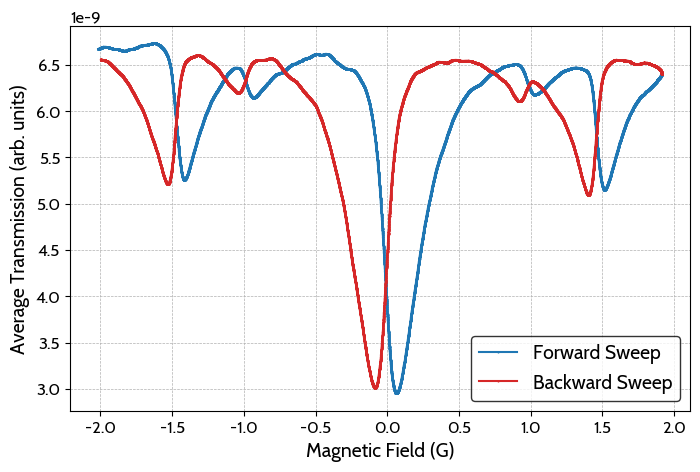

In [4]:
fig = plot_average(590, range(444, 474))
fig.savefig("figures/frequency_sweep.svg", format='svg', bbox_inches='tight')

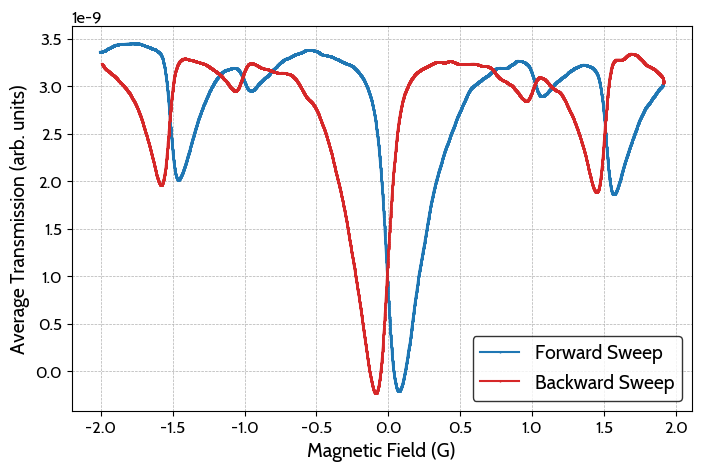

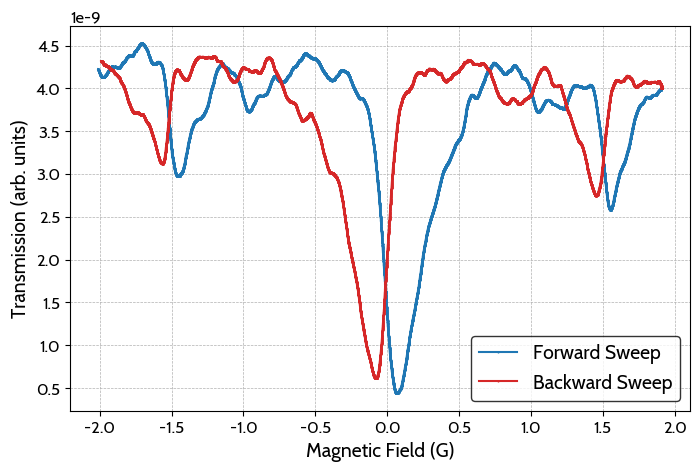

In [6]:
plot_average(610, range(504, 534))
plot_single_trace(610, 505)

## Peak 2

(1.5196719708450002, 0.0012102511049999487)

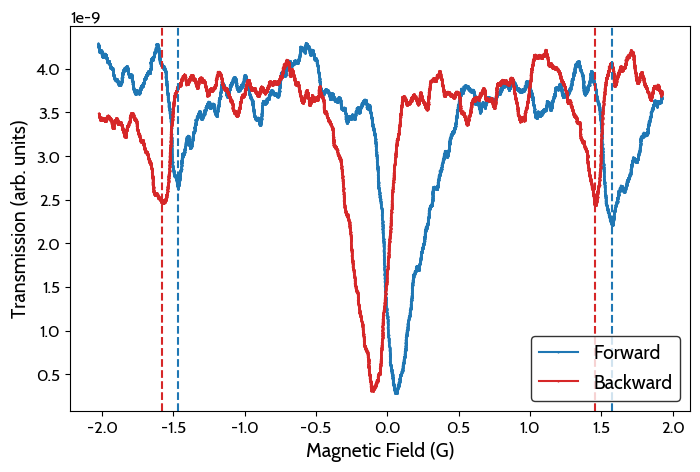

In [7]:
peak_2(610, 509, True)

In [8]:
frequencies = []
all_peak_2_locations = {}
average_peak_2_locations = []
peak_2_errors = []


for frequency in all_data_numbers:
    frequencies.append(frequency)
    specific_peak_2_locations = []
    specific_peak_2_errors = []

    for data_num in all_data_numbers[frequency]:
        peak2_location, peak2_error = peak_2(frequency, data_num, plot = False)
        specific_peak_2_locations.append(peak2_location)
        #sketchy fix to divide by 0
        if peak2_error == 0.0:
            peak2_error = specific_peak_2_errors[-1]
        specific_peak_2_errors.append(peak2_error)

    all_peak_2_locations[frequency] = specific_peak_2_locations

    weights = 1 / np.array(specific_peak_2_errors)**2
    average_peak_2_location = np.average(specific_peak_2_locations, weights=weights)
    average_peak_2_locations.append(average_peak_2_location)

    peak_2_errors.append(np.std(specific_peak_2_locations) / np.sqrt(len(specific_peak_2_locations)))


average_peak_2_locations = np.array(average_peak_2_locations)
peak_2_errors = np.array(peak_2_errors)


m = 0.00239 ± 0.00003, b = 0.04 ± 0.01


(0.29900668567978395, 0.0031927991605427927)

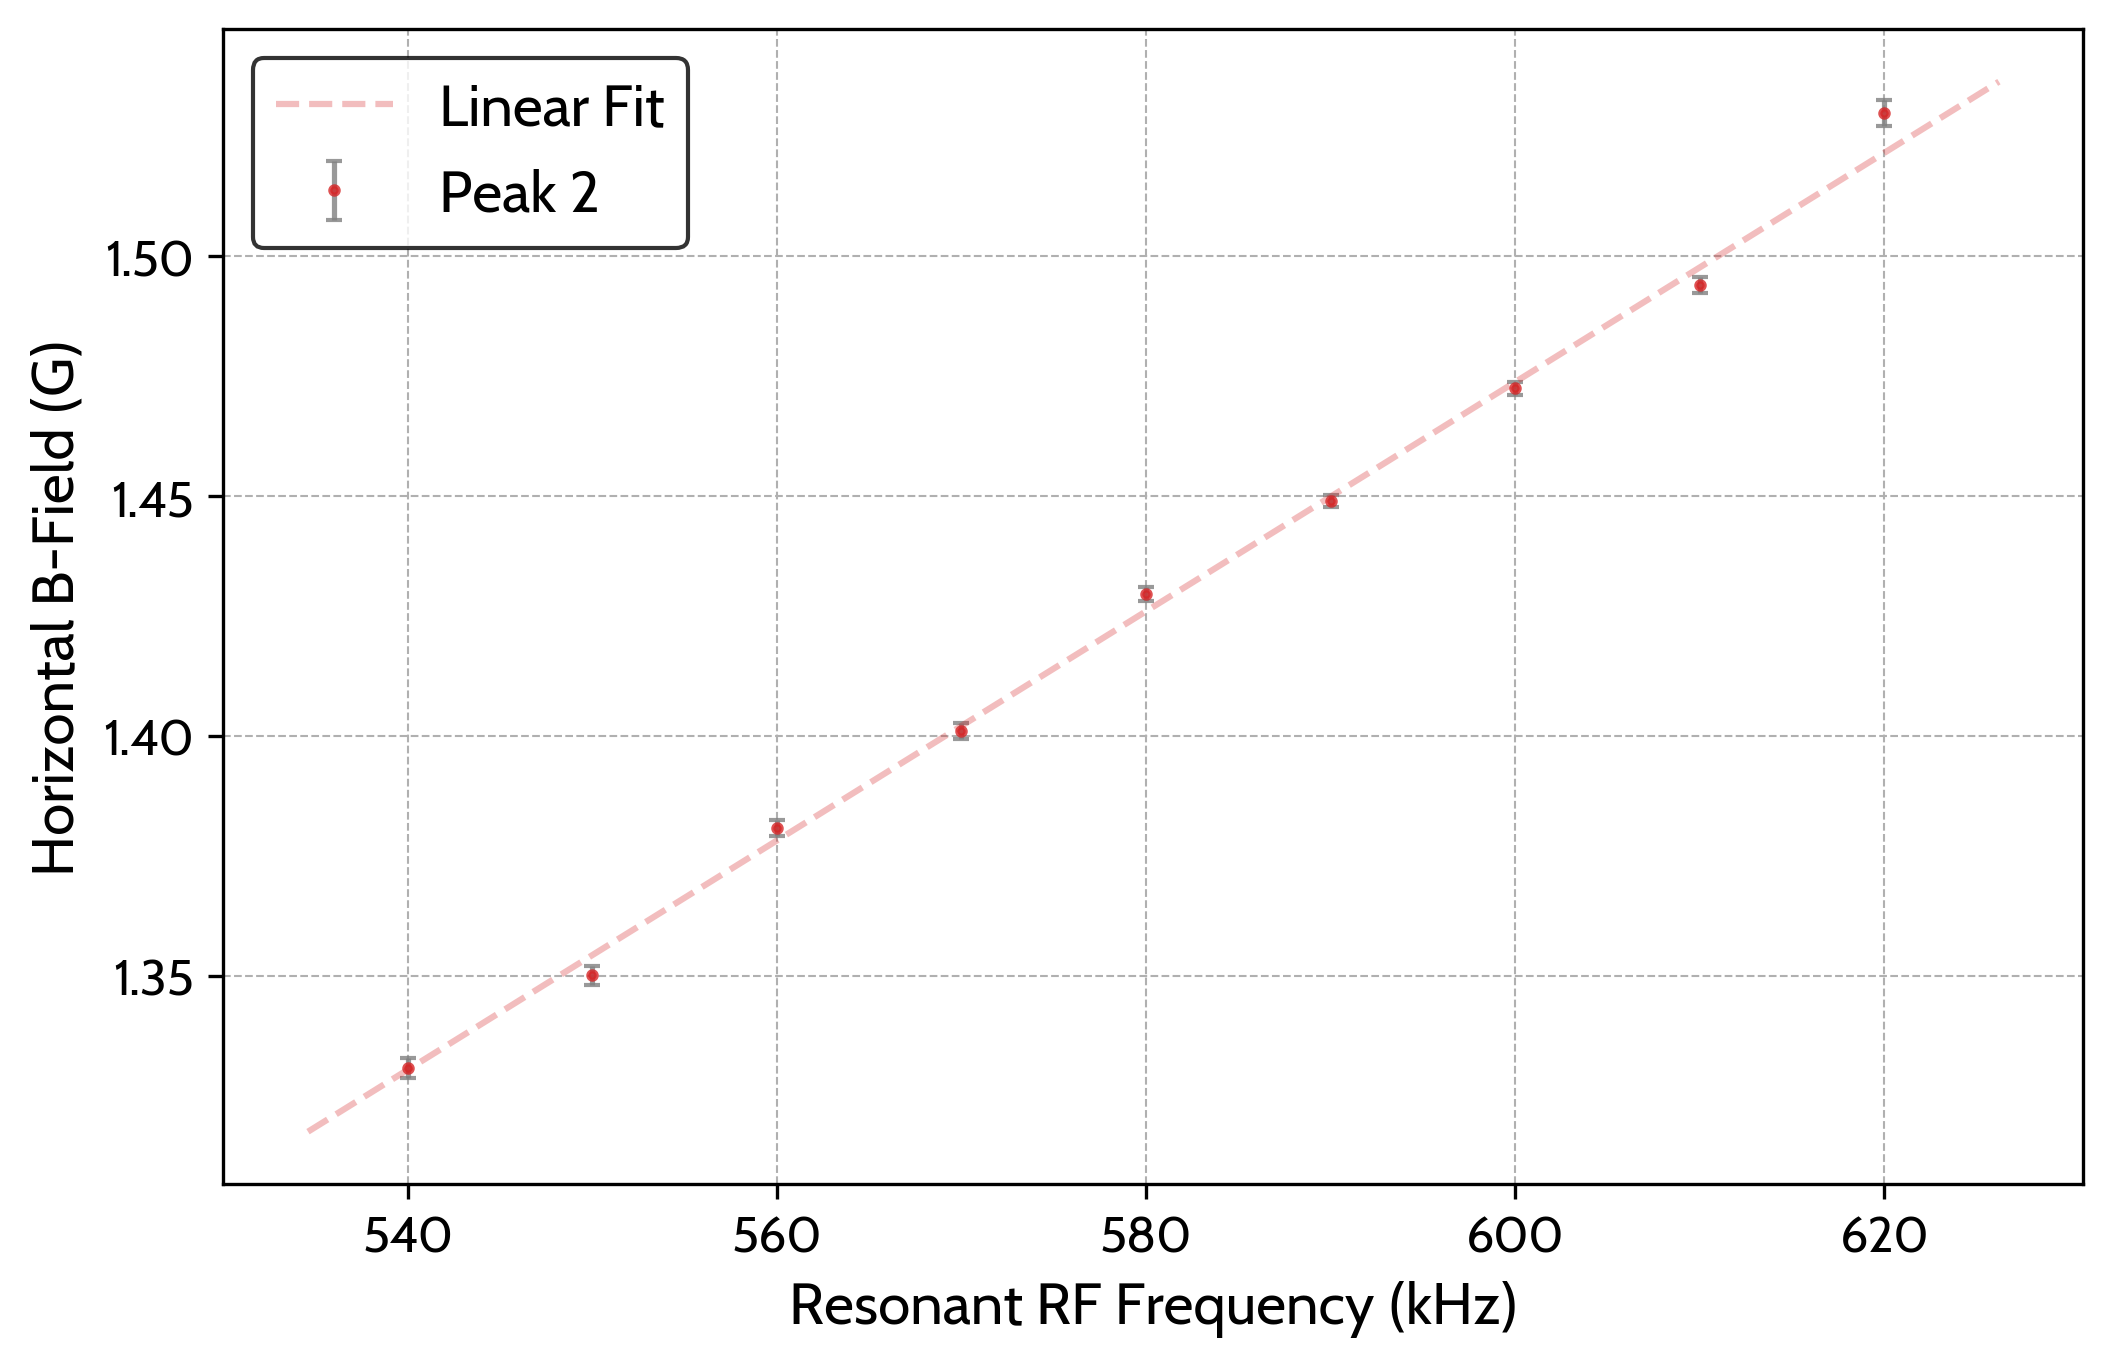

In [9]:
fig, ax = plt.subplots(figsize=(8, 5), dpi = 300)

corrected_peak_2 = corrected_field(average_peak_2_locations)
corrected_peak_2_errors = np.sqrt(corrected_field_error(average_peak_2_locations)**2 + peak_2_errors**2)

ax.errorbar(frequencies, corrected_peak_2, yerr=corrected_peak_2_errors, color = "tab:red", fmt='o', ms=2, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label  = "Peak 2")

def f(x, m, b):
    return m * x + b

popt, pcov = curve_fit(f, frequencies, corrected_peak_2, sigma=corrected_peak_2_errors, absolute_sigma=True)

x_fit = np.linspace(min(frequencies)*0.99, max(frequencies)*1.01, 100)
ax.plot(x_fit, f(x_fit, *popt), color = "tab:red", alpha = 0.3, linestyle='--', label = f"Linear Fit")
ax.set_xlabel("Resonant RF Frequency (kHz)")
ax.set_ylabel("Horizontal B-Field (G)")
ax.legend(loc = "upper left")
ax.grid(True, linestyle='--', linewidth=0.5)

print(f"m = {popt[0]:.5f} ± {np.sqrt(pcov[0, 0]):.5f}, b = {popt[1]:.2f} ± {np.sqrt(pcov[1, 1]):.2f}")

slope = popt[0] 
mu_b = 9.274009994e-24  # Bohr magneton in J/T
h = 6.62607015e-34  # Planck's constant in J*s

g = (1 / (slope * 1e-7)) * (h / mu_b)   # Convert from G/kHz to T/Hz
g_error = (1 / (slope * 1e-7)) * (h / mu_b) * (np.sqrt(pcov[0, 0]) / slope)
g, g_error

In [28]:
# field = 0.00239 G/kHz, so 1 kHz corresponds to 0.2999 G
1000 * 0.00239
5 / 0.00239

2092.0502092050206

## Peak 1

(0.9541485239475003, 0.06790853422499987)

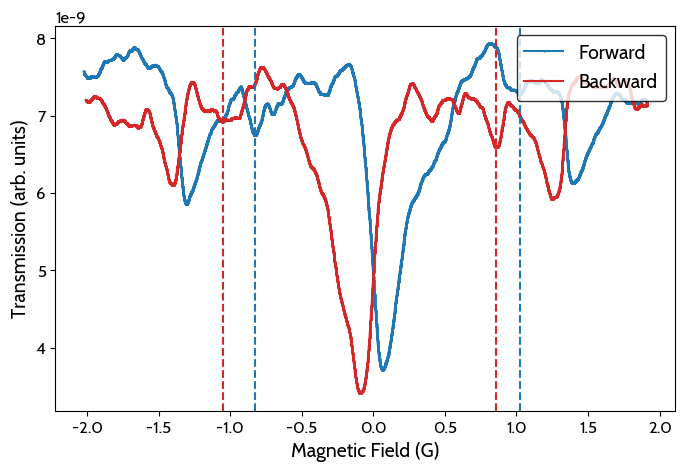

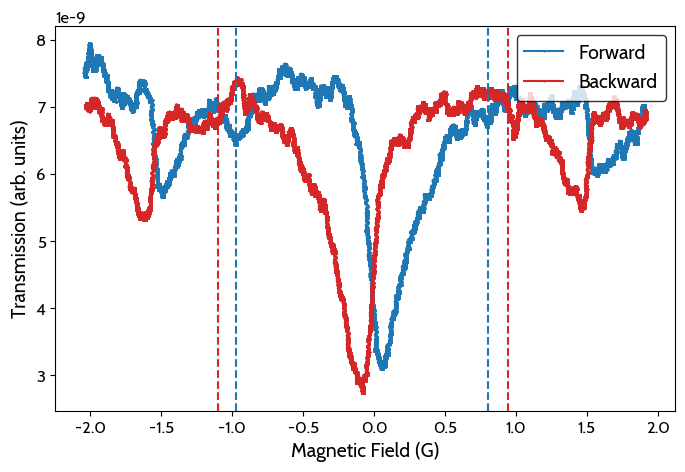

In [10]:
peak_1(540, 384, True)
peak_1(620, 258, True)

In [11]:
frequencies = []
all_peak_1_locations = {}
average_peak_1_locations = []
peak_1_errors = []

for frequency in all_data_numbers:
    frequencies.append(frequency)
    specific_peak_1_locations = []
    specific_peak_1_errors = []

    for data_num in all_data_numbers[frequency]:
        peak1_location, peak1_error = peak_1(frequency, data_num, plot = False)
        specific_peak_1_locations.append(peak1_location)
        if peak1_error == 0.0:
            peak1_error = specific_peak_1_errors[-1]
        specific_peak_1_errors.append(peak1_error)

    all_peak_1_locations[frequency] = specific_peak_1_locations

    weights = 1 / np.array(specific_peak_1_errors)**2
    average_peak_1_location = np.average(specific_peak_1_locations, weights=weights)
    average_peak_1_locations.append(average_peak_1_location)

    peak_1_errors.append(np.std(specific_peak_1_locations) / np.sqrt(len(specific_peak_1_locations)))

average_peak_1_locations = np.array(average_peak_1_locations)
peak_1_errors = np.array(peak_1_errors)


m = 0.00141 ± 0.00007, b = 0.14 ± 0.04


(0.5084253077997991, 0.023915709576094294)

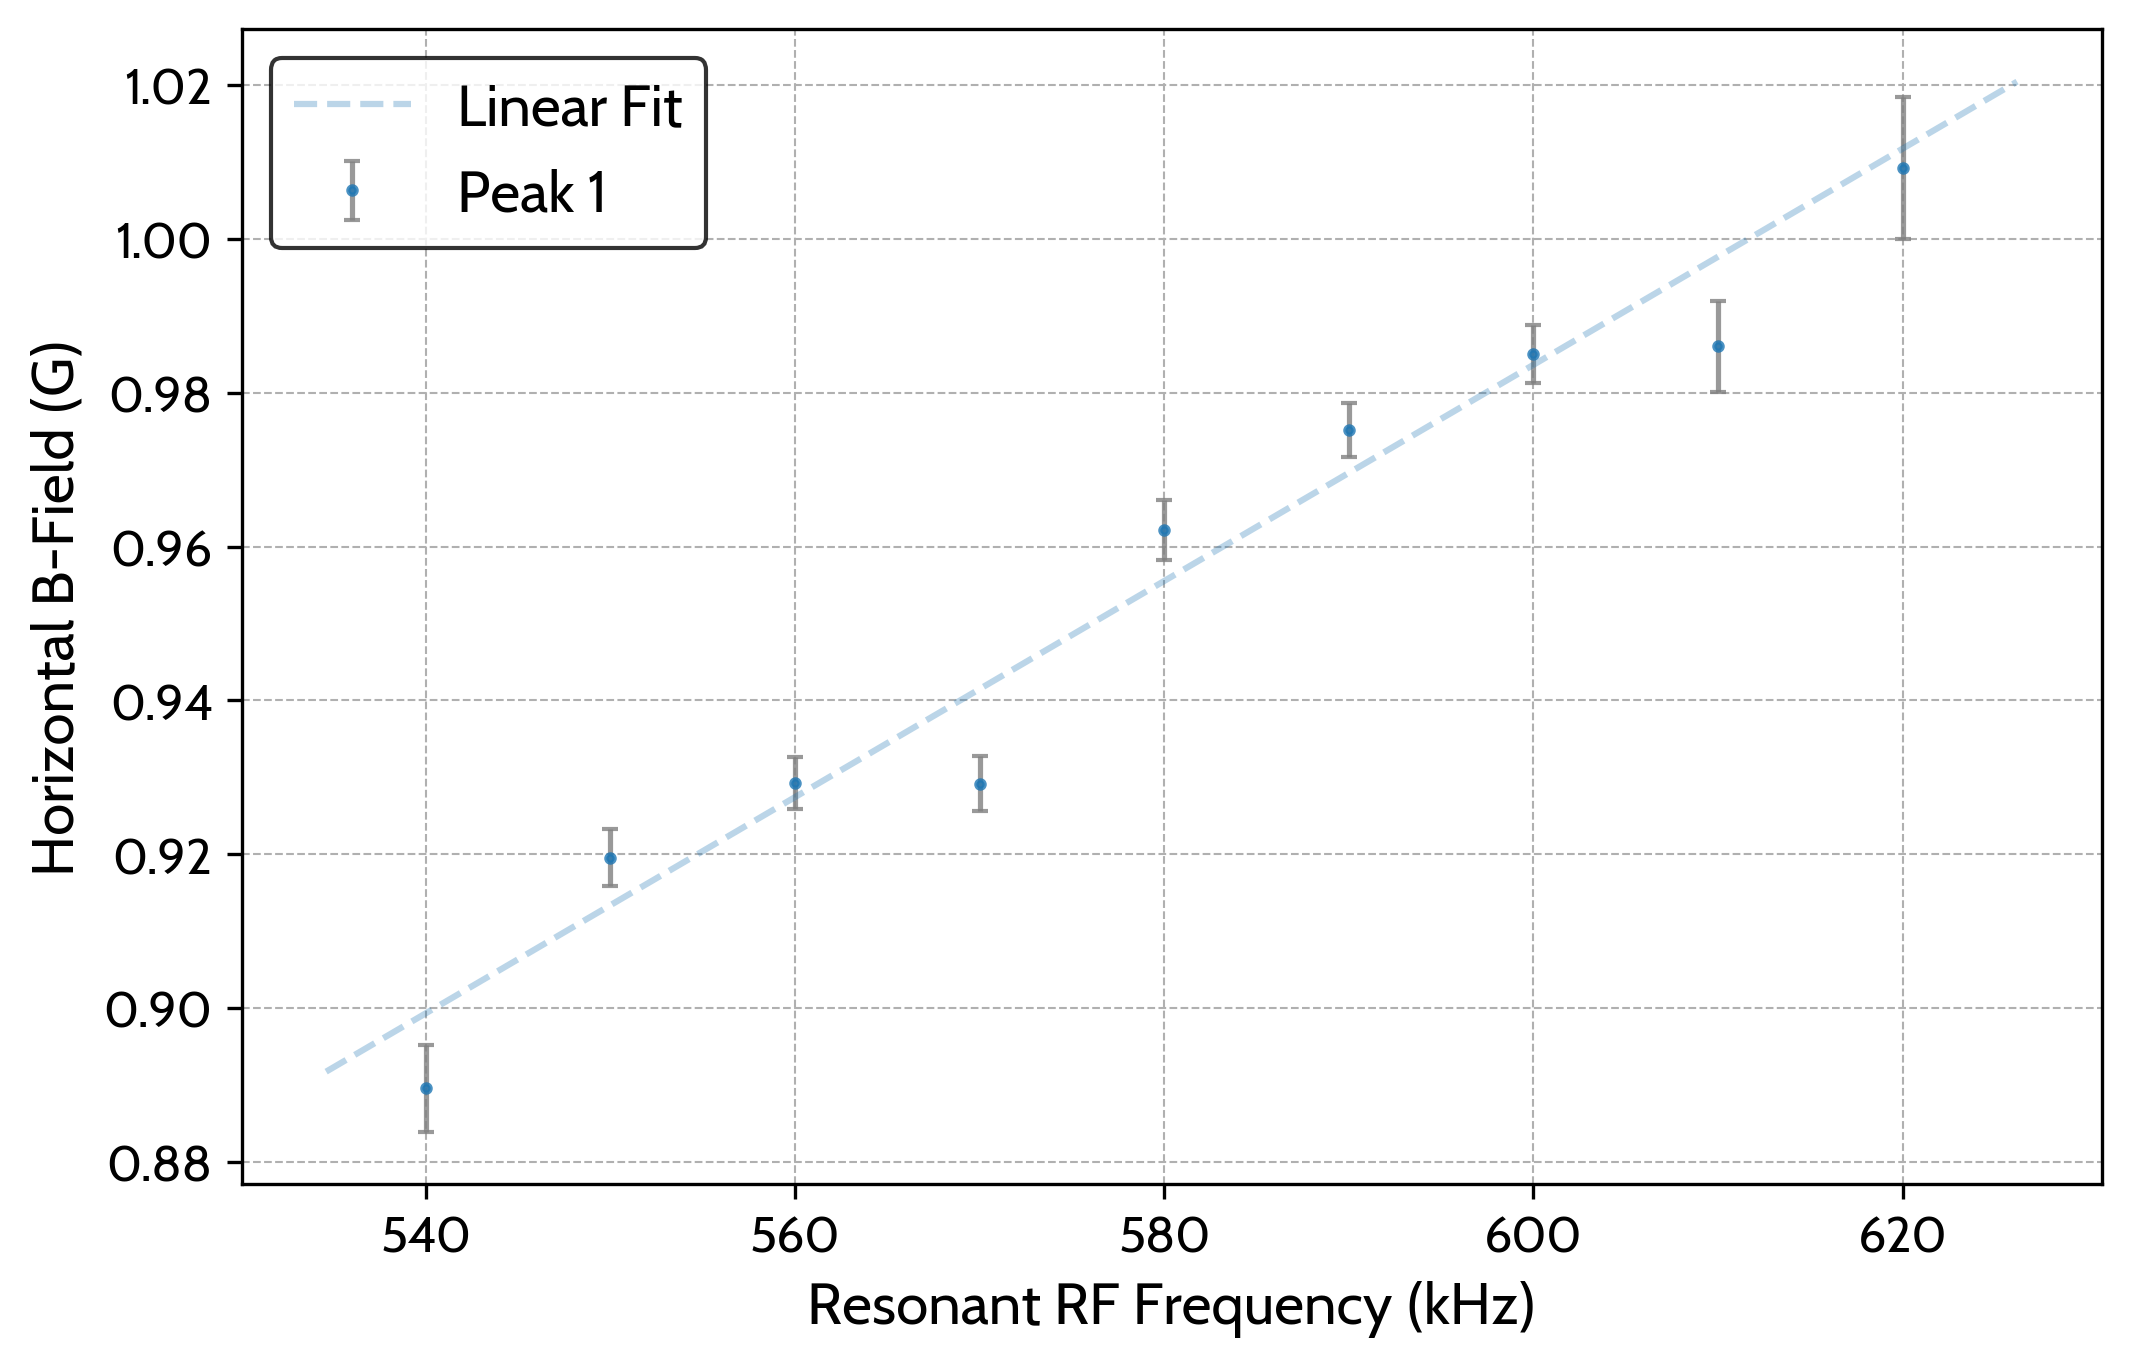

In [12]:
fig, ax = plt.subplots(figsize=(8, 5), dpi = 300)

corrected_peak_1 = corrected_field(average_peak_1_locations)
corrected_peak_1_errors = np.sqrt(corrected_field_error(average_peak_1_locations)**2 + peak_1_errors**2)

ax.errorbar(frequencies, corrected_peak_1, yerr=corrected_peak_1_errors, color = "tab:blue", fmt='o', ms=2, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label  = "Peak 1")

def f(x, m, b):
    return m * x + b

popt, pcov = curve_fit(f, frequencies, corrected_peak_1, sigma=corrected_peak_1_errors, absolute_sigma=True)

x_fit = np.linspace(min(frequencies)*0.99, max(frequencies)*1.01, 100)
ax.plot(x_fit, f(x_fit, *popt), color = "tab:blue", alpha = 0.3, linestyle='--', label = f"Linear Fit")
ax.set_xlabel("Resonant RF Frequency (kHz)")
ax.set_ylabel("Horizontal B-Field (G)")
ax.legend(loc = "upper left")
ax.grid(True, linestyle='--', linewidth=0.5)

print(f"m = {popt[0]:.5f} ± {np.sqrt(pcov[0, 0]):.5f}, b = {popt[1]:.2f} ± {np.sqrt(pcov[1, 1]):.2f}")

slope = popt[0] 
mu_b = 9.274009994e-24  # Bohr magneton in J/T
h = 6.62607015e-34  # Planck's constant in J*s

g = (1 / (slope * 1e-7)) * (h / mu_b)   # Convert from G/kHz to T/Hz
g_error = (1 / (slope * 1e-7)) * (h / mu_b) * (np.sqrt(pcov[0, 0]) / slope)


g, g_error

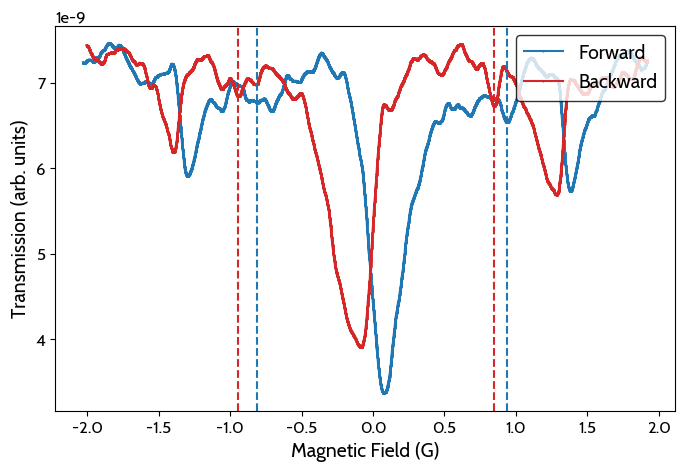

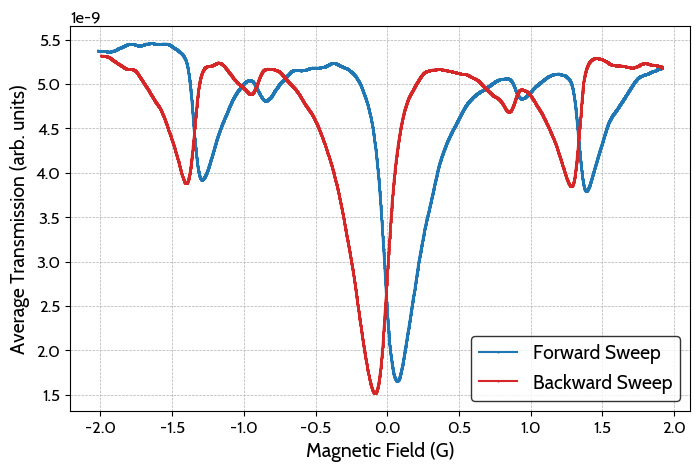

In [13]:
peak_1(540, 385, True)
plot_average(540, range(384, 414))

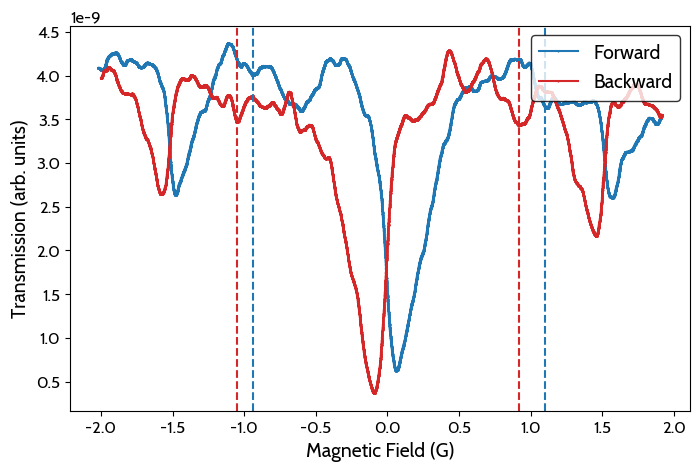

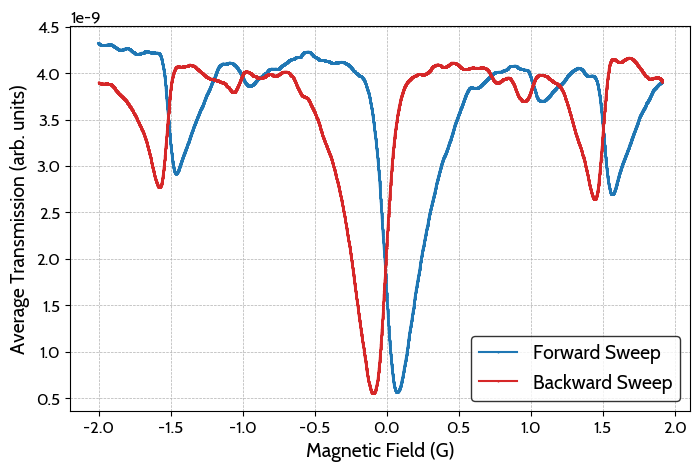

In [14]:
peak_1(610, 507, True)
plot_average(610, range(504, 510))

## Both

Reduced chi-squared for $\mathregular{^87Rb}$ fit: 3.94
Reduced chi-squared for $\mathregular{^85Rb}$ fit: 4.17
m = 1.405274946482149e-10 ± 6.610243406821194e-12, b = 1.4046396573073846e-05 ± 3.8047989430858943e-06
m = 2.3895029439143605e-10 ± 2.5515157079661402e-12, b = 4.012313392682196e-06 ± 1.4849616461235423e-06


(0.508425314820802,
 0.023915711964896173,
 0.29900668626277244,
 0.0031927989824385434)

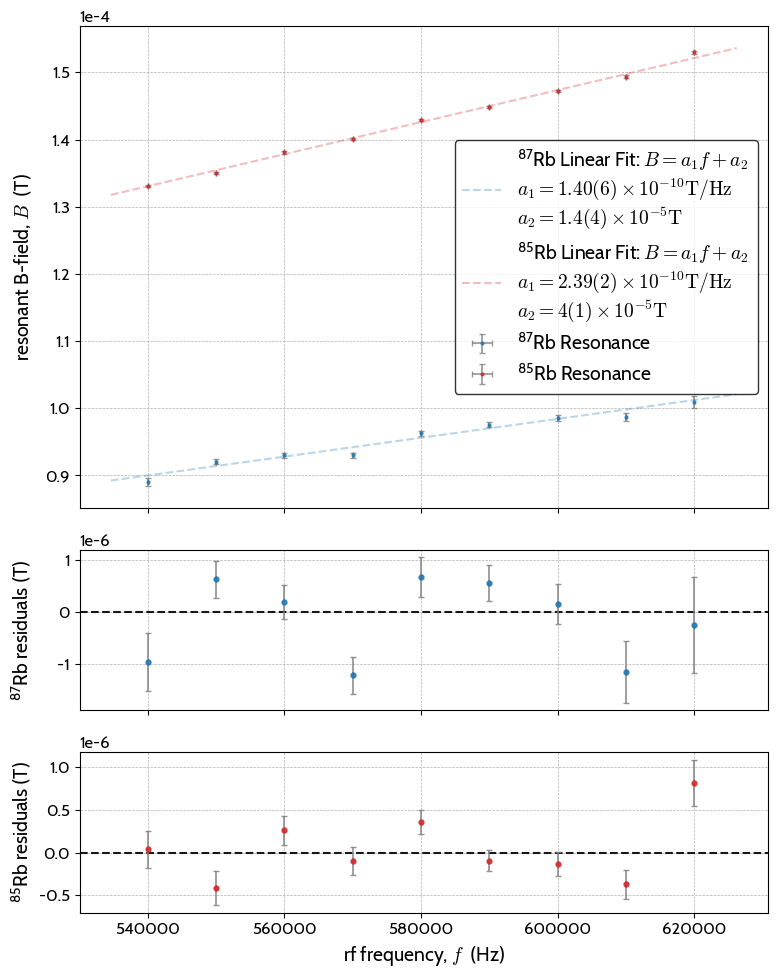

In [32]:
frequencies = np.array(frequencies)
frequencies_Hz = frequencies * 1e3
peak1_locations_T = corrected_field(average_peak_1_locations) * 1e-4  # Convert G to T
peak1_errors_T = np.sqrt(corrected_field_error(average_peak_1_locations)**2 + peak_1_errors**2) * 1e-4  # Convert G to T
peak2_locations_T = corrected_field(average_peak_2_locations) * 1e-4  # Convert G to T
peak2_errors_T = np.sqrt(corrected_field_error(average_peak_2_locations)**2 + peak_2_errors**2) * 1e-4  # Convert G to T

fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1, 1]}, tight_layout=True)


fig.align_ylabels() 

ax = axs[0]

freq_error = 0.01e3

ax.errorbar(frequencies_Hz, peak1_locations_T, xerr=freq_error, yerr=peak1_errors_T, color = "tab:blue", fmt='o', ms=2, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label  = "$\mathregular{^{87}Rb}$ Resonance", zorder = 300)
ax.errorbar(frequencies_Hz, peak2_locations_T, xerr=freq_error, yerr=peak2_errors_T, color = "tab:red", fmt='o', ms=2, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label  = "$\mathregular{^{85}Rb}$ Resonance", zorder = 300)

def f(x, m, b):
    return m * x + b

popt1, pcov1 = curve_fit(f, frequencies_Hz, peak1_locations_T, sigma=peak1_errors_T, absolute_sigma=True)

x_fit = np.linspace(min(frequencies_Hz)*0.99, max(frequencies_Hz)*1.01, 100)
ax.plot(x_fit, f(x_fit, *popt1), color = "tab:blue", alpha = 0.3, linestyle='--', label = "$\mathregular{^{87}Rb}$ Linear Fit: $B=a_{1}f+a_{2}$ \n$a_{1} = 1.40(6) \\times 10^{-10} \\mathrm{T/Hz}$\n$a_{2} = 1.4(4) \\times 10^{-5} \\mathrm{T}$")

popt2, pcov2 = curve_fit(f, frequencies_Hz, peak2_locations_T, sigma=peak2_errors_T, absolute_sigma=True)

x_fit = np.linspace(min(frequencies_Hz)*0.99, max(frequencies_Hz)*1.01, 100)
ax.plot(x_fit, f(x_fit, *popt2), color = "tab:red", alpha = 0.3, linestyle='--', label = "$\mathregular{^{85}Rb}$ Linear Fit: $B=a_{1}f+a_{2}$ \n$a_{1} = 2.39(2) \\times 10^{-10} \\mathrm{T/Hz}$\n$a_{2} = 4(1) \\times 10^{-5} \\mathrm{T}$")
ax.set_ylabel("resonant B-field, $B$  (T)")
ax.legend(loc = "center right")
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax.grid(True, linestyle='--', linewidth=0.5)


# residuals
residuals1 = peak1_locations_T - f(frequencies_Hz, *popt1)
residuals2 = peak2_locations_T - f(frequencies_Hz, *popt2)

chi_21 = np.sum((residuals1 / peak1_errors_T)**2) / (len(frequencies_Hz) - 2)
chi_22 = np.sum((residuals2 / peak2_errors_T)**2) / (len(frequencies_Hz) - 2)
print(f"Reduced chi-squared for $\mathregular{{^{87}Rb}}$ fit: {chi_21:.2f}")
print(f"Reduced chi-squared for $\mathregular{{^{85}Rb}}$ fit: {chi_22:.2f}")


axs[1].errorbar(frequencies_Hz, residuals1, xerr=freq_error, yerr=peak1_errors_T, color = "tab:blue", fmt='o', ms=3.5, ecolor='gray', alpha=0.85, elinewidth=1.25, capsize=2, zorder = 100)
axs[1].axhline(y=0, color='black', linestyle='--', alpha=0.9)
axs[1].set_ylabel("$\mathregular{^{87}Rb}$ residuals (T)")
axs[1].grid(True, linestyle='--', linewidth=0.5)


axs[2].errorbar(frequencies_Hz, residuals2, xerr=freq_error, yerr=peak2_errors_T, color = "tab:red", fmt='o', ms=3.5, ecolor='gray', alpha=0.85, elinewidth=1.25, capsize=2, zorder = 100)
axs[2].axhline(y=0, color='black', linestyle='--', alpha=0.9)
axs[2].set_ylabel("$\mathregular{^{85}Rb}$ residuals (T)")
axs[2].grid(True, linestyle='--', linewidth=0.5)

axs[2].set_xlabel("rf frequency, $f$  (Hz)")

#reduce ax label fontsize
for ax in axs:
    ax.xaxis.label.set_fontsize(14)
    ax.yaxis.label.set_fontsize(14)


fig.savefig("figures/varying_rf.svg", format='svg')

# results

print(f"m = {popt1[0]} ± {np.sqrt(pcov1[0, 0])}, b = {popt1[1]} ± {np.sqrt(pcov1[1, 1])}")
print(f"m = {popt2[0]} ± {np.sqrt(pcov2[0, 0])}, b = {popt2[1]} ± {np.sqrt(pcov2[1, 1])}")


slope1 = popt1[0] 
slope2 = popt2[0]

mu_b = 9.274009994e-24  # Bohr magneton 
h = 6.62607015e-34  # Planck's constant 

g1 = (1 / (slope1)) * (h / mu_b)   
g1_error = (1 / (slope1)) * (h / mu_b) * (np.sqrt(pcov1[0, 0]) / slope1)


g2 = (1 / (slope2)) * (h / mu_b)  
g2_error = (1 / (slope2)) * (h / mu_b) * (np.sqrt(pcov2[0, 0]) / slope2)


g1, g1_error, g2, g2_error

## Field Systematics

(array([ 0.99187341, -0.00556023]), array([0.00052203, 0.00059851]))

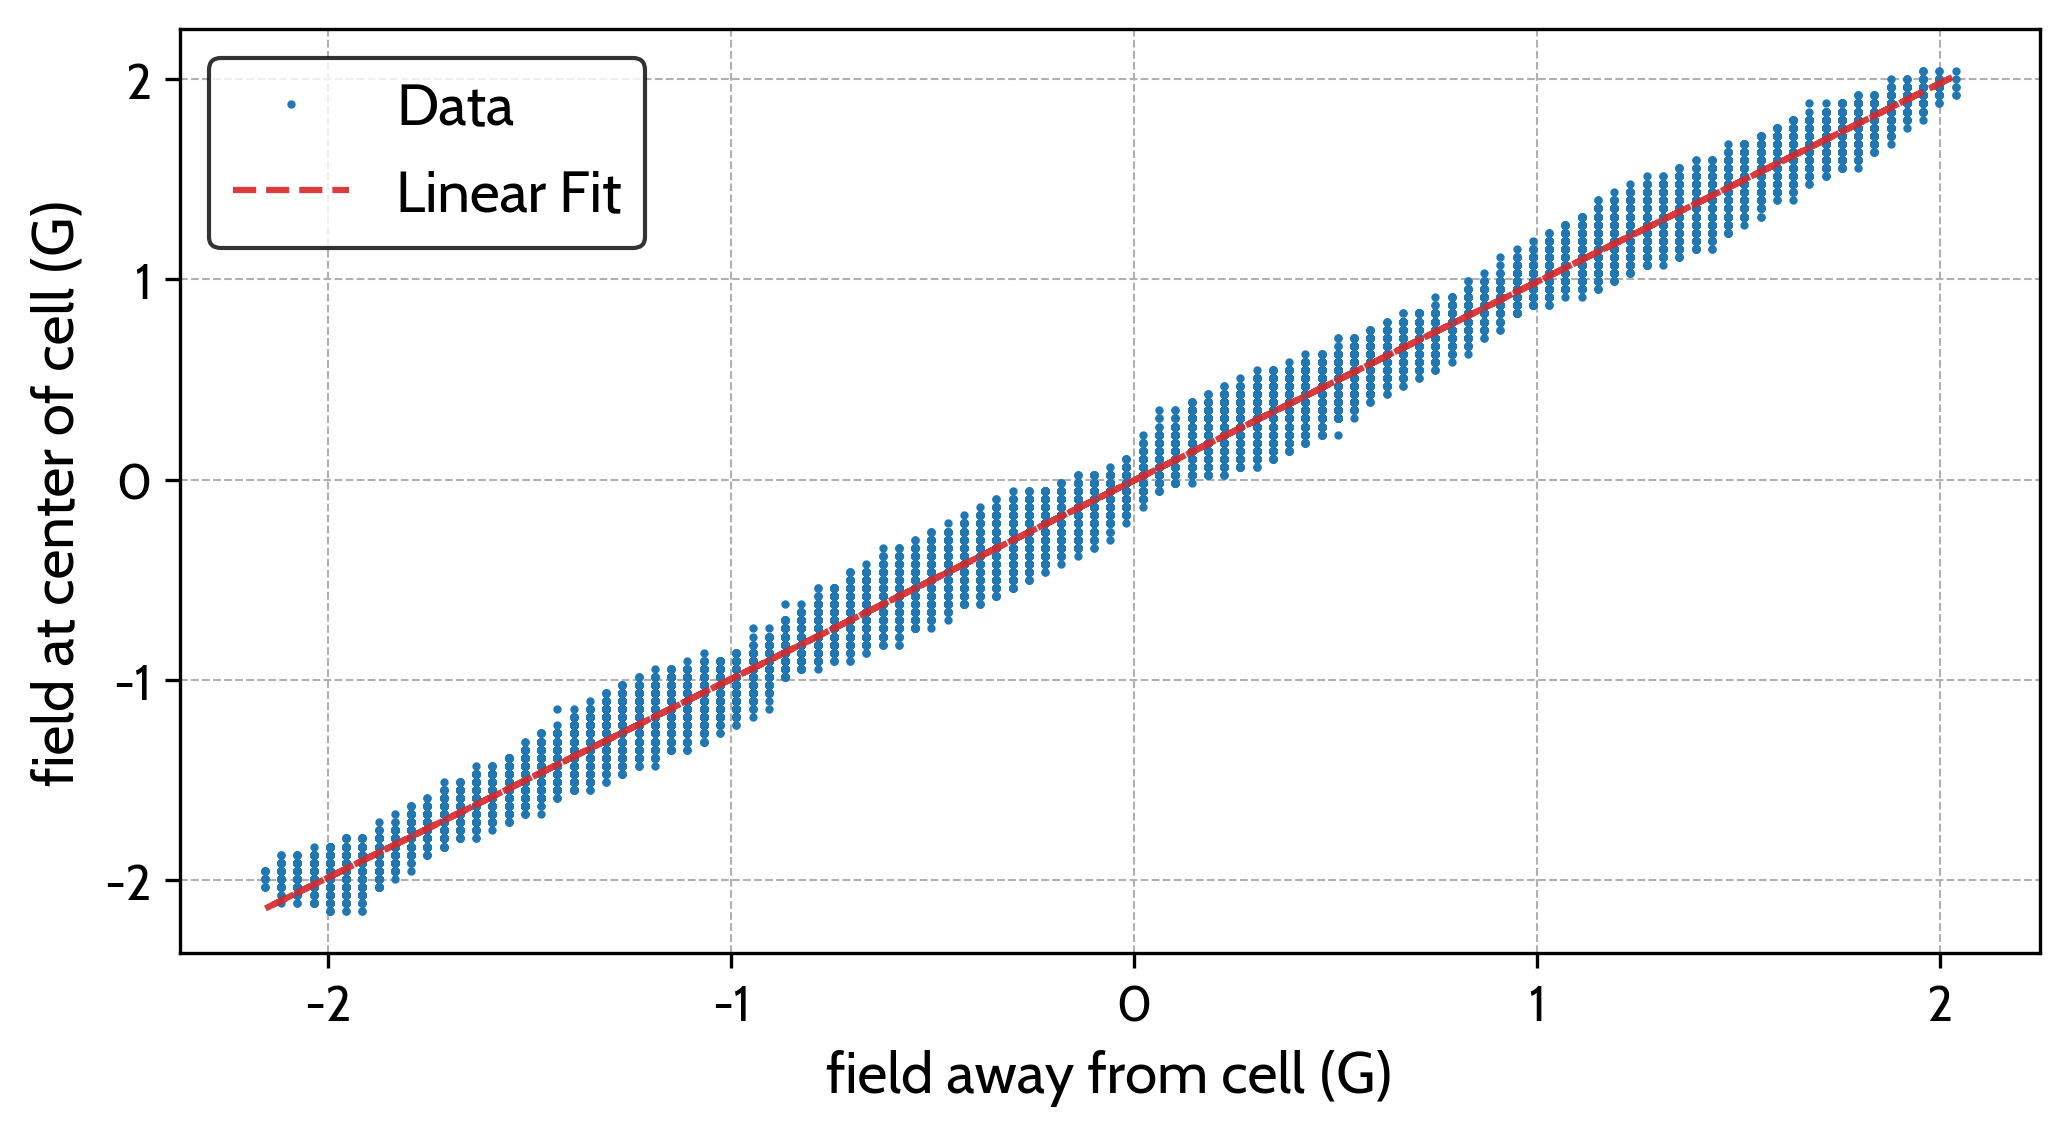

In [16]:
data1 = load_waveforms(f"data/25/SWEEP_LAMP_ON_534.npz")
t, V1, V2, V3 = data1[1][0], data1[1][1], data1[2][1], data1[3][1]
N = 1
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

field_1 = gaussmeter(V1[t < 2.5]*1e3)
awg_1 = V3[t < 2.5]

data2 = load_waveforms(f"data/25/SWEEP_CENTERED_536.npz")
t, V1, V2, V3 = data2[1][0], data2[1][1], data2[2][1], data2[3][1]
N = 1
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

field_2 = gaussmeter(V1[t < 2.5]*1e3)
awg_2 = V3[t < 2.5]

def f(x, m, b):
    return m * x + b

popt, pcov = curve_fit(f, field_1, field_2)

fig, ax = plt.subplots(figsize=(8, 4), dpi = 300)
ax.plot(field_1, field_2,  'o', markersize = 1, color = "tab:blue", label = "Data")
ax.plot(field_1, f(field_1, *popt), color = "tab:red", alpha = 0.9, linestyle='--', label = f"Linear Fit", zorder = 100)

ax.set_xlabel("field away from cell (G)")
ax.set_ylabel("field at center of cell (G)")

ax.grid(True, linestyle='--', linewidth=0.5)
ax.legend()

popt, np.sqrt(np.diag(pcov)) # 0.9919(5)